Khai phá dữ liệu MNIST

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

In [17]:
sys.path.append(os.path.abspath('..')) 
from src.data import load_prepared_mnist
X_train, y_train, X_test, y_test = load_prepared_mnist()


In [18]:

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test :", X_test.shape, X_test.dtype)
print("y_test :", y_test.shape, y_test.dtype)

print("Pixel min:", X_train.min())
print("Pixel max:", X_train.max())

print("Nhãn train:", np.unique(y_train))
print("Nhãn test :", np.unique(y_test))

print("NaN trong train:", np.isnan(X_train).sum())
print("NaN trong test :", np.isnan(X_test).sum())

X_train: (60000, 784) float32
y_train: (60000, 10) float32
X_test : (10000, 784) float32
y_test : (10000, 10) float32
Pixel min: 0.0
Pixel max: 1.0
Nhãn train: [0. 1.]
Nhãn test : [0. 1.]
NaN trong train: 0
NaN trong test : 0


Vẽ biểu đồ phân phối các nhãn của tập train

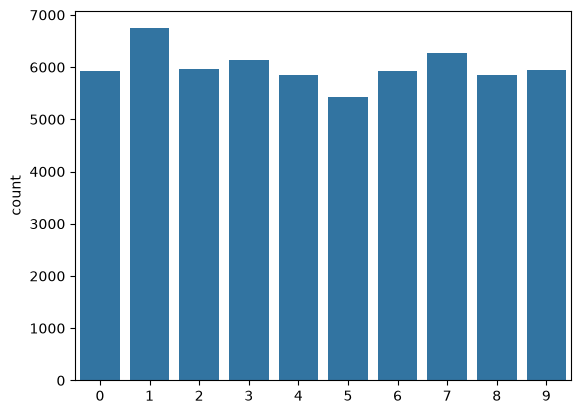

[0.09871667 0.11236667 0.0993     0.10218333 0.09736667 0.09035
 0.09863333 0.10441667 0.09751667 0.09915   ]


In [3]:
y_train_labels = np.argmax(y_train, axis = 1)
sns.countplot(x = y_train_labels)
plt.show()
print(np.bincount(y_train_labels)/len(y_train_labels))

Nhận xét: Các lớp trong mẫu phân bố khá đồng đều (9% - 11,2%), lớp 1 nhiều nhất, lớp 5 ít nhất

Trực quan hóa mẫu ảnh (code lớp thực hành)

In [4]:
# Cac ham ve hinh dung chung cho ca notebook
MEAN = X_train.mean().item()
STD = X_train.std().item()
def show_images(X, titles, n_cols=10, size=1.4):
    n = len(X)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * 1.25 * n_rows))
    for ax in np.array(axes).reshape(-1):
        ax.axis("off")
    for k in range(n):
        ax = np.array(axes).reshape(-1)[k]
        ax.imshow((X[k] * STD + MEAN).reshape(28, 28), cmap="gray_r")
        ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()



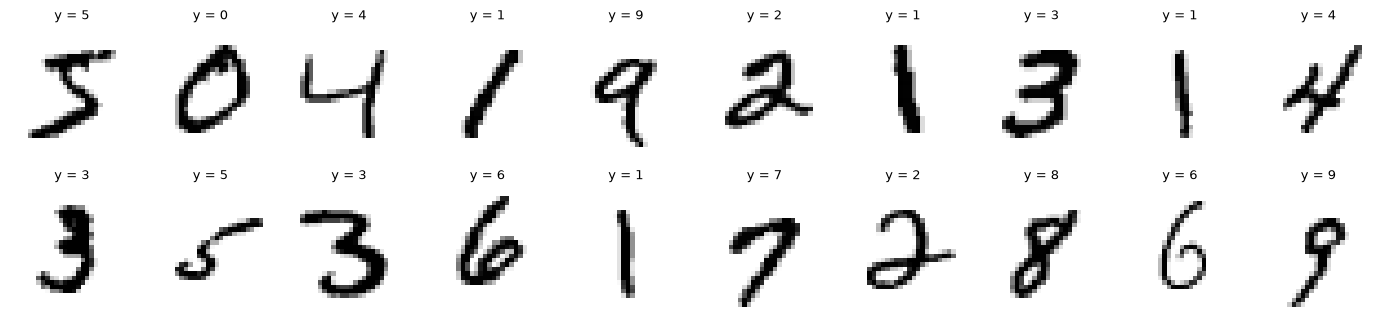

In [5]:
show_images(X_train[:20], [f"y = {int(t)}" for t in y_train_labels[:20]])

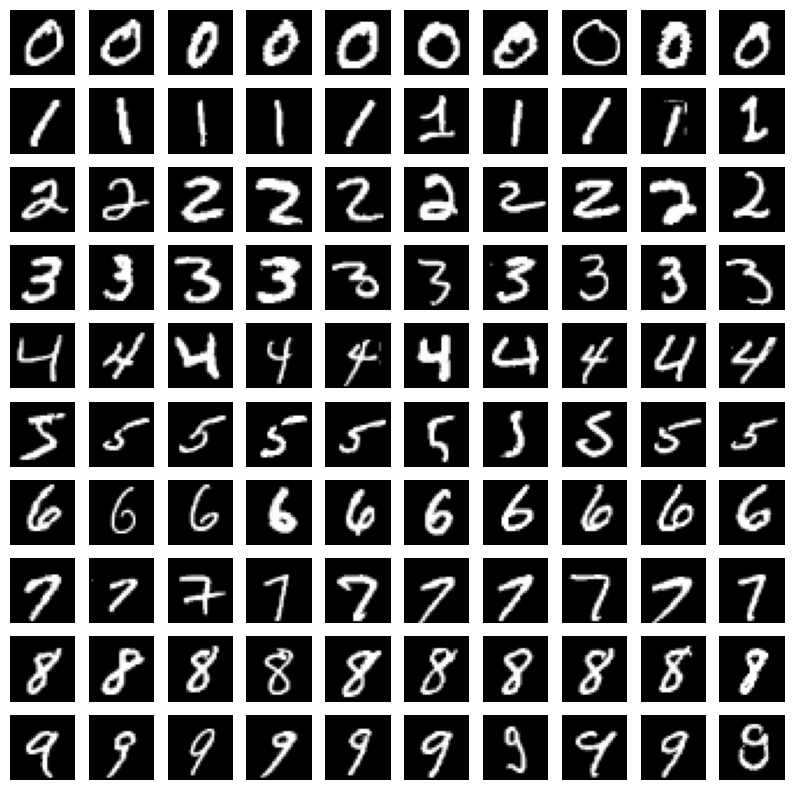

In [6]:
fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for digit in range(10):
    idx = np.where(y_train_labels == digit)[0][:10]
    for j, i in enumerate(idx):
        axes[digit, j].imshow(X_train[i].reshape(28,28), cmap="gray")
        axes[digit, j].axis("off")
plt.show()

<Axes: >

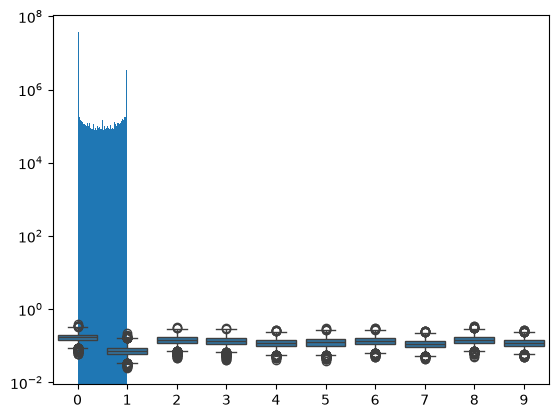

In [11]:
plt.hist(X_train.ravel(), bins=50, log=True)
mean_intensity = X_train.reshape(len(X_train), -1).mean(axis=1)
sns.boxplot(x=y_train_labels, y=mean_intensity)

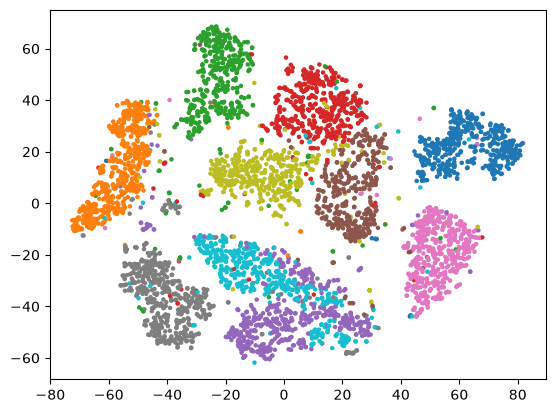

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xf = X_train[:5000].reshape(5000, -1) / 255.0
Xp = PCA(n_components=50).fit_transform(Xf)
Xt = TSNE(n_components=2, random_state=42).fit_transform(Xp)
plt.scatter(Xt[:, 0], Xt[:, 1], c=y_train_labels[:5000], cmap="tab10", s=5)